# Erasing and repainting: diffusion smoke test

A three-scene engineering demonstration with masks, denoising snapshots, and background preservation. Read `PAPER_NOTES.md` for connections to Attentive Eraser, RePaint, and PowerPaint. This is a standard inpainting baseline, **not a reproduction** of those methods.

Run from this folder using Python 3.12. Tiny mode checks execution; the full pretrained model is needed to assess visual removal. The drawn people and known clean backgrounds make the test self-contained.

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os
import sys
import subprocess
import json
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'run_smoke.py').exists() and (ROOT / 'erasing_smoke/run_smoke.py').exists():
    ROOT = ROOT / 'erasing_smoke'
assert (ROOT / 'run_smoke.py').exists(), 'Open this notebook from the erasing_smoke directory.'
os.environ['HF_HOME'] = str(ROOT / '.cache/huggingface')

# Prefer the isolated environment used to validate this project when present.
candidate = ROOT.parent / '.venv-inpainting' / 'bin' / 'python'
SMOKE_PYTHON = str(candidate) if candidate.exists() else sys.executable
os.environ['USE_TORCH'] = '1'
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
print('Smoke-test Python:', SMOKE_PYTHON)

def run(*args):
    subprocess.run([SMOKE_PYTHON, '-u', '-X', 'faulthandler', *args], cwd=ROOT, check=True)

run('make_dataset.py', '--output', 'data')
run('-m', 'unittest', '-v', 'test_smoke.py')

Smoke-test Python: /Users/haowenzhang/Documents/ChatGPT/DSC180a checkpoint/.venv-inpainting/bin/python
data/manifest.json


test_composite_only_changes_white_mask (test_smoke.SmokeTests.test_composite_only_changes_white_mask) ... ok
test_dataset_covers_all_changed_pixels (test_smoke.SmokeTests.test_dataset_covers_all_changed_pixels) ... ok
test_rejects_empty_and_full_masks (test_smoke.SmokeTests.test_rejects_empty_and_full_masks) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.052s

OK


## 1. Inspect the small dataset
White mask pixels are replaced. Black pixels are preserved. Clean backgrounds are evaluation-only references and never enter the model.

brick_wall an empty brick wall, continuous brickwork, no people


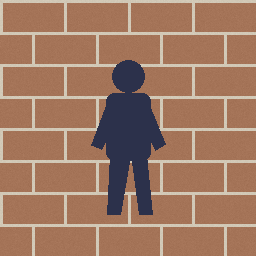

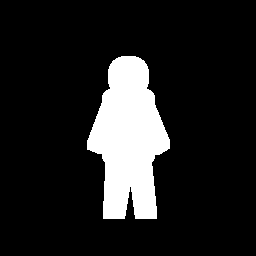

beach an empty beach, blue sea and sand, no people


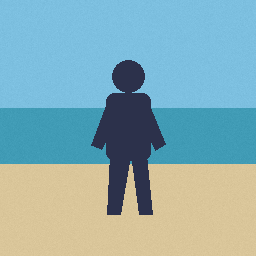

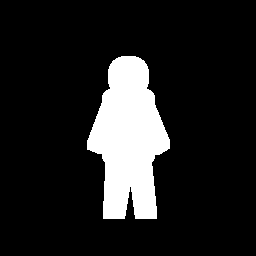

park an empty park path surrounded by grass, no people


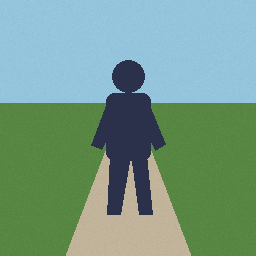

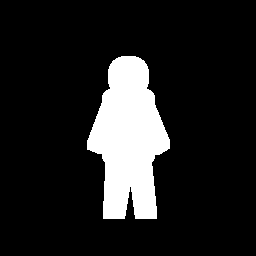

In [3]:
for row in json.loads((ROOT / 'data/manifest.json').read_text()):
    print(row['id'], row['prompt'])
    display(Image(filename=str(ROOT / 'data' / row['image']), width=256))
    display(Image(filename=str(ROOT / 'data' / row['mask']), width=256))

## 2. Tiny model: verify the diffusion path
Expected: generated images look like noise. Passing means mask handling, diffusion calls, snapshots, and output writing work. It does not establish removal quality.

Loading hf-internal-testing/tiny-stable-diffusion-pipe on cpu


/Users/haowenzhang/Documents/ChatGPT/DSC180a checkpoint/.venv-inpainting/lib/python3.12/site-packages/diffusers/pipelines/pipeline_loading_utils.py:964: FutureWarning: You are using a legacy checkpoint for inpainting with Stable Diffusion, therefore we are loading the <class 'diffusers.pipelines.deprecated.stable_diffusion_variants.pipeline_stable_diffusion_inpaint_legacy.StableDiffusionInpaintPipelineLegacy'> class instead of <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_inpaint.StableDiffusionInpaintPipeline'>. For better inpainting results, we strongly suggest using Stable Diffusion's official inpainting checkpoint: https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-inpainting instead or adapting your checkpoint hf-internal-testing/tiny-stable-diffusion-pipe to the format of https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-inpainting. Note that we do not actively maintain the {StableDiffusionInpaintPipelineLegacy} class and will likel

{'id': 'brick_wall', 'seconds': 0.14458200000808574, 'prompt': 'an empty brick wall, continuous brickwork, no people', 'mask_fraction': 0.13330078125, 'raw_outside_mae': 31.41192488262911, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 95.54884004884005, 'masked_reference_mae': 78.83699633699634, 'masked_reference_psnr_db': 8.730823884028782}
{'id': 'beach', 'seconds': 0.08752195800479967, 'prompt': 'an empty beach, blue sea and sand, no people', 'mask_fraction': 0.13330078125, 'raw_outside_mae': 61.290704225352115, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 96.1978021978022, 'masked_reference_mae': 84.76373626373626, 'masked_reference_psnr_db': 7.99379571306452}


100%|██████████| 4/4 [00:00<00:00, 55.76it/s]


{'id': 'park', 'seconds': 0.08704862499143928, 'prompt': 'an empty park path surrounded by grass, no people', 'mask_fraction': 0.13330078125, 'raw_outside_mae': 51.870892018779344, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 93.74969474969475, 'masked_reference_mae': 81.7960927960928, 'masked_reference_psnr_db': 8.264546131794233}
PASS: generated 3 cases; unmasked pixels preserved exactly.


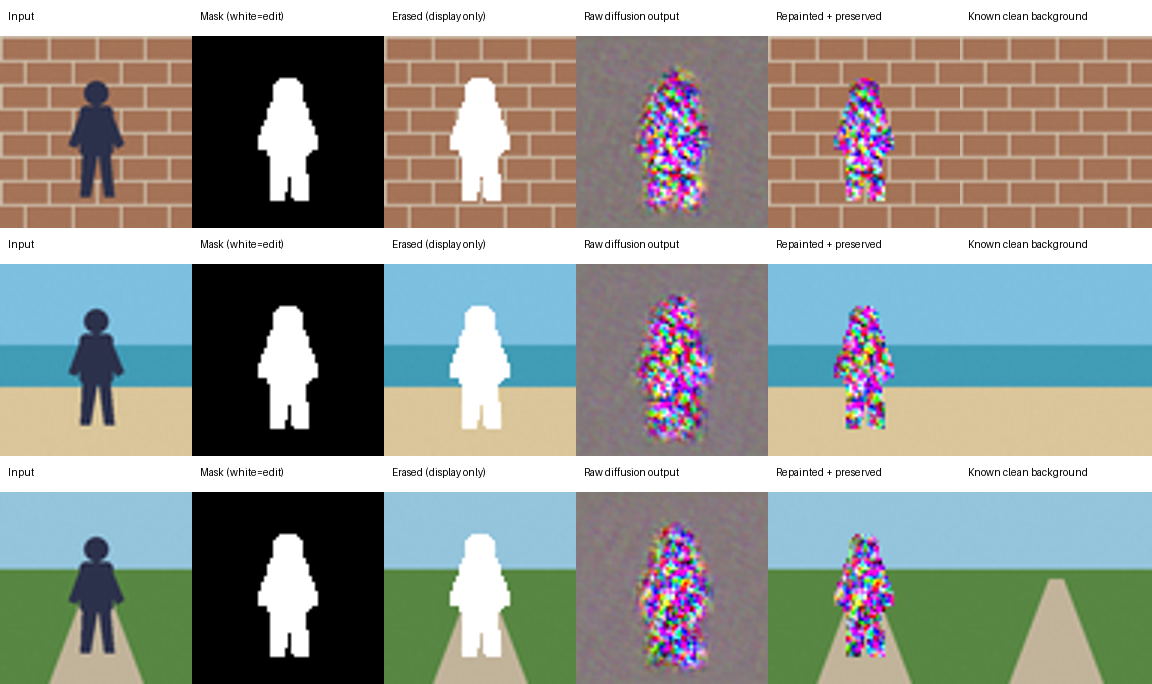

[
  {
    "id": "brick_wall",
    "seconds": 0.14458200000808574,
    "prompt": "an empty brick wall, continuous brickwork, no people",
    "mask_fraction": 0.13330078125,
    "raw_outside_mae": 31.41192488262911,
    "final_outside_max_error": 0.0,
    "edited_region_change_mae": 95.54884004884005,
    "masked_reference_mae": 78.83699633699634,
    "masked_reference_psnr_db": 8.730823884028782
  },
  {
    "id": "beach",
    "seconds": 0.08752195800479967,
    "prompt": "an empty beach, blue sea and sand, no people",
    "mask_fraction": 0.13330078125,
    "raw_outside_mae": 61.290704225352115,
    "final_outside_max_error": 0.0,
    "edited_region_change_mae": 96.1978021978022,
    "masked_reference_mae": 84.76373626373626,
    "masked_reference_psnr_db": 7.99379571306452
  },
  {
    "id": "park",
    "seconds": 0.08704862499143928,
    "prompt": "an empty park path surrounded by grass, no people",
    "mask_fraction": 0.13330078125,
    "raw_outside_mae": 51.870892018779344,
    "f

In [4]:
run('run_smoke.py', '--mode', 'tiny', '--device', 'cpu', '--output', 'outputs/tiny')
display(Image(filename=str(ROOT / 'outputs/tiny/contact_sheet.png')))
print((ROOT / 'outputs/tiny/metrics.json').read_text())

## 3. Full pretrained model: inspect erasing and repainting
Downloads several GB on first use. The smaller CPU example below uses 256×256 and 16 steps; use `--size 512 --steps 30` for the standard settings. No training is needed. The last column is a known reference, not model input.

Loading stable-diffusion-v1-5/stable-diffusion-inpainting on mps


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]`torch_dtype` is deprecated! Use `dtype` instead!
An error occurred while trying to fetch /Users/haowenzhang/Documents/ChatGPT/DSC180a checkpoint/erasing_smoke/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /Users/haowenzhang/Documents/ChatGPT/DSC180a checkpoint/erasing_smoke/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Loading pipeline components...:  57%|█████▋    | 4/7 [00:00<00:00, 32.34it/s]An error occurred while trying to fetch /Users/haowenzhang/Documents/ChatGPT/DSC180a checkpoint/erasing_smoke/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inp

{'id': 'brick_wall', 'seconds': 6.270058416994289, 'prompt': 'an empty brick wall, continuous brickwork, no people', 'mask_fraction': 0.1326141357421875, 'raw_outside_mae': 8.30881050810684, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 53.40547693015763, 'masked_reference_mae': 8.614582134775437, 'masked_reference_psnr_db': 27.676627033680102}


100%|██████████| 16/16 [00:02<00:00,  6.22it/s]


{'id': 'beach', 'seconds': 2.8959245000005467, 'prompt': 'an empty beach, blue sea and sand, no people', 'mask_fraction': 0.1326141357421875, 'raw_outside_mae': 3.817339549066174, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 73.5754995589307, 'masked_reference_mae': 4.533233613316457, 'masked_reference_psnr_db': 32.80261654987837}


100%|██████████| 16/16 [00:02<00:00,  6.28it/s]


{'id': 'park', 'seconds': 2.8697530409990577, 'prompt': 'an empty park path surrounded by grass, no people', 'mask_fraction': 0.1326141357421875, 'raw_outside_mae': 3.0492157035212712, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 68.6434242319641, 'masked_reference_mae': 11.57783914394201, 'masked_reference_psnr_db': 18.18774279164575}
PASS: generated 3 cases; unmasked pixels preserved exactly.


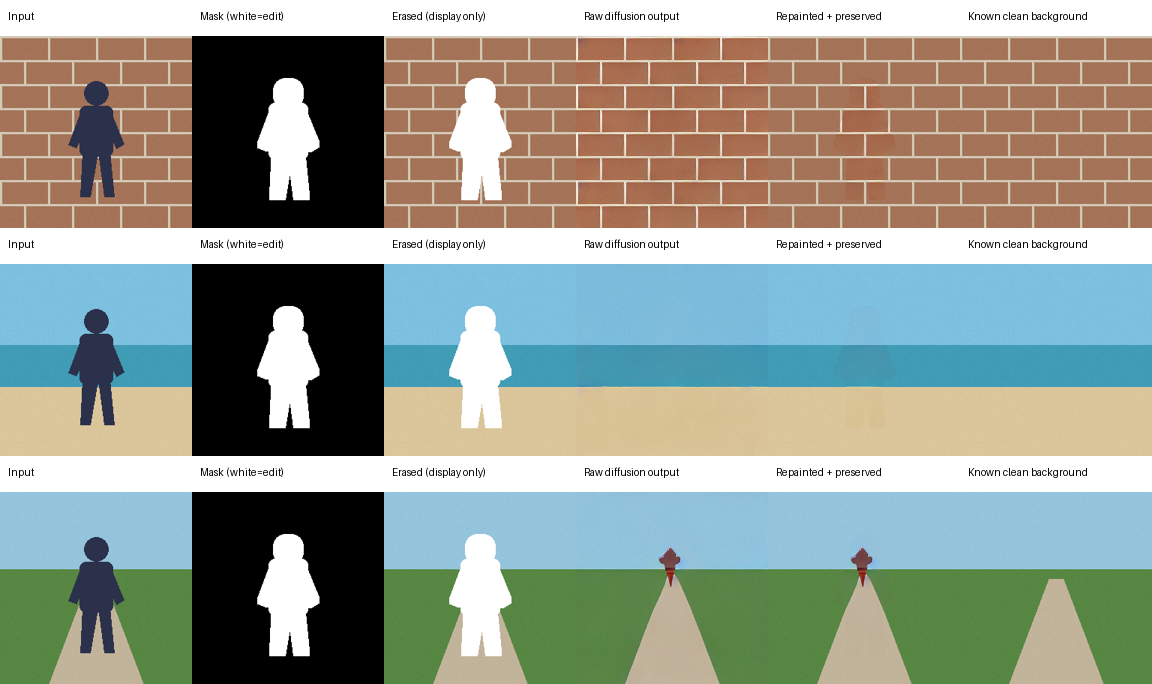

[
  {
    "id": "brick_wall",
    "seconds": 6.270058416994289,
    "prompt": "an empty brick wall, continuous brickwork, no people",
    "mask_fraction": 0.1326141357421875,
    "raw_outside_mae": 8.30881050810684,
    "final_outside_max_error": 0.0,
    "edited_region_change_mae": 53.40547693015763,
    "masked_reference_mae": 8.614582134775437,
    "masked_reference_psnr_db": 27.676627033680102
  },
  {
    "id": "beach",
    "seconds": 2.8959245000005467,
    "prompt": "an empty beach, blue sea and sand, no people",
    "mask_fraction": 0.1326141357421875,
    "raw_outside_mae": 3.817339549066174,
    "final_outside_max_error": 0.0,
    "edited_region_change_mae": 73.5754995589307,
    "masked_reference_mae": 4.533233613316457,
    "masked_reference_psnr_db": 32.80261654987837
  },
  {
    "id": "park",
    "seconds": 2.8697530409990577,
    "prompt": "an empty park path surrounded by grass, no people",
    "mask_fraction": 0.1326141357421875,
    "raw_outside_mae": 3.0492157035212

In [5]:
run('run_smoke.py', '--mode', 'quality', '--size', '256', '--steps', '16',
    '--output', 'outputs/quality')
display(Image(filename=str(ROOT / 'outputs/quality/contact_sheet.png')))
print((ROOT / 'outputs/quality/metrics.json').read_text())

## 4. Inside denoising
These panels decode the current **noisy latents**, not predicted clean images. Early panels can look highly distorted.

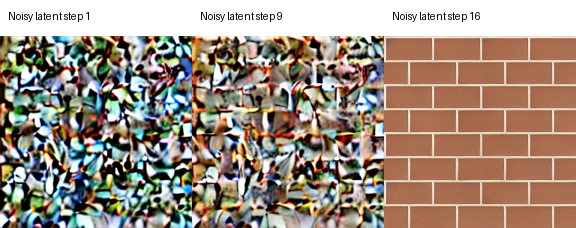

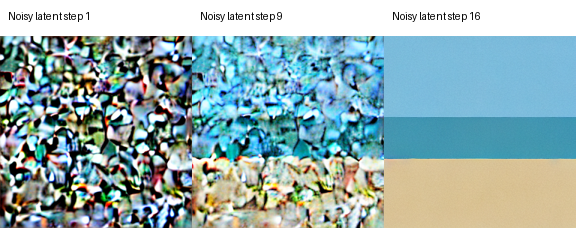

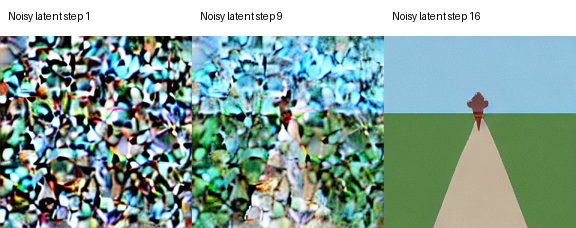

In [6]:
for case in sorted((ROOT / 'outputs/quality').glob('[0-9][0-9]')):
    display(Image(filename=str(case / 'trajectory.png')))

## What this experiment establishes
- A small batch completes diffusion inference and writes images and metrics.
- Final compositing preserves pixels outside the mask exactly; raw-output error is recorded separately.
- The model generates replacement pixels without seeing the reference.

Inspect whether the person is gone, structures continue naturally, and new objects or seams appear. Pixel error against one reference is not a complete quality measure. Do not compute or report FID from three cases.

For your own photos and masks, follow the manifest example in `README.md`. For paper-specific extensions, consult `PAPER_NOTES.md`.

## 5. Real pedestrian photos: Penn-Fudan

Prepare three images and their annotated person masks. This downloads a roughly 51 MB archive; selected images are included with this project. All labeled people are selected. Mask dilation helps remove boundaries but may miss shadows and reflections. Square padding retains image geometry. No clean background is available.

Prepared 3 real photos: data/pennfudan/manifest.json
Loading stable-diffusion-v1-5/stable-diffusion-inpainting on mps


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]An error occurred while trying to fetch /Users/haowenzhang/Documents/ChatGPT/DSC180a checkpoint/erasing_smoke/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /Users/haowenzhang/Documents/ChatGPT/DSC180a checkpoint/erasing_smoke/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Loading pipeline components...:  14%|█▍        | 1/7 [00:00<00:00,  7.59it/s]`torch_dtype` is deprecated! Use `dtype` instead!
An error occurred while trying to fetch /Users/haowenzhang/Documents/ChatGPT/DSC180a checkpoint/erasing_smoke/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-i

{'id': 'FudanPed00001', 'seconds': 3.1886600840080064, 'prompt': 'an empty outdoor campus walkway, continuous pavement, trees and buildings, no people', 'mask_fraction': 0.1427154541015625, 'raw_outside_mae': 11.05574640015663, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 68.08147118571581}


100%|██████████| 16/16 [00:02<00:00,  6.19it/s]


{'id': 'FudanPed00002', 'seconds': 2.9116299160086783, 'prompt': 'an empty outdoor campus walkway, continuous pavement, trees and buildings, no people', 'mask_fraction': 0.1056671142578125, 'raw_outside_mae': 11.956356315367422, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 67.15870036101083}


100%|██████████| 16/16 [00:02<00:00,  6.23it/s]


{'id': 'FudanPed00003', 'seconds': 2.8939713750005467, 'prompt': 'an empty outdoor campus walkway, continuous pavement, trees and buildings, no people', 'mask_fraction': 0.1035003662109375, 'raw_outside_mae': 9.44438014512734, 'final_outside_max_error': 0.0, 'edited_region_change_mae': 56.20497321735712}
PASS: generated 3 cases; unmasked pixels preserved exactly.


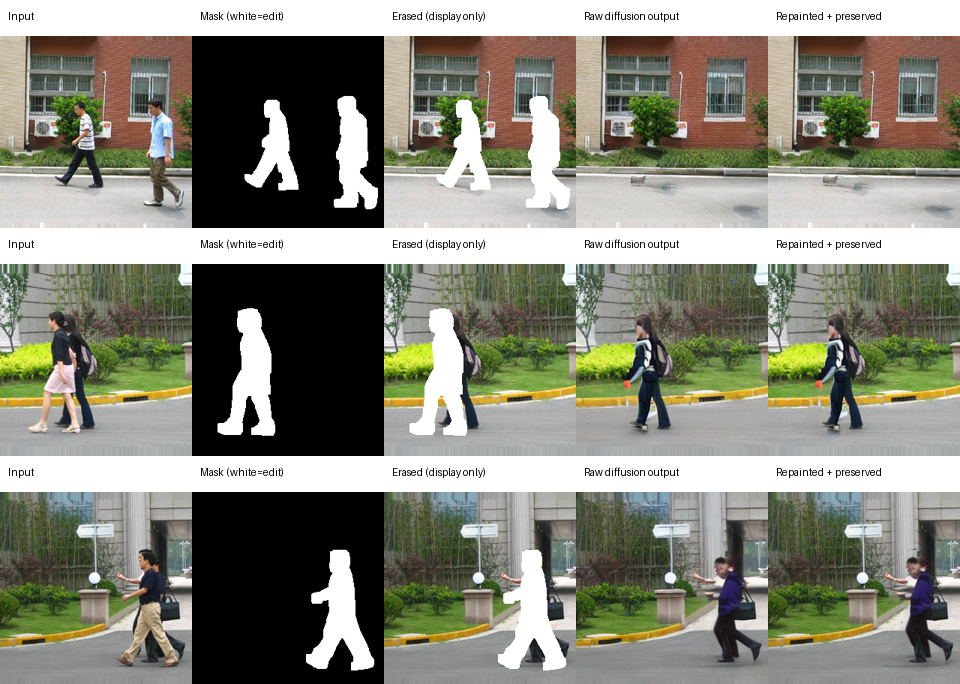

[
  {
    "id": "FudanPed00001",
    "seconds": 3.1886600840080064,
    "prompt": "an empty outdoor campus walkway, continuous pavement, trees and buildings, no people",
    "mask_fraction": 0.1427154541015625,
    "raw_outside_mae": 11.05574640015663,
    "final_outside_max_error": 0.0,
    "edited_region_change_mae": 68.08147118571581
  },
  {
    "id": "FudanPed00002",
    "seconds": 2.9116299160086783,
    "prompt": "an empty outdoor campus walkway, continuous pavement, trees and buildings, no people",
    "mask_fraction": 0.1056671142578125,
    "raw_outside_mae": 11.956356315367422,
    "final_outside_max_error": 0.0,
    "edited_region_change_mae": 67.15870036101083
  },
  {
    "id": "FudanPed00003",
    "seconds": 2.8939713750005467,
    "prompt": "an empty outdoor campus walkway, continuous pavement, trees and buildings, no people",
    "mask_fraction": 0.1035003662109375,
    "raw_outside_mae": 9.44438014512734,
    "final_outside_max_error": 0.0,
    "edited_region_change_m

In [7]:
run('prepare_pennfudan.py', '--count', '3')
run('run_smoke.py', '--mode', 'quality', '--manifest', 'data/pennfudan/manifest.json',
    '--size', '256', '--steps', '16', '--output', 'outputs/pennfudan')
display(Image(filename=str(ROOT / 'outputs/pennfudan/contact_sheet.png')))
print((ROOT / 'outputs/pennfudan/metrics.json').read_text())

## Saved result preview
The image below was produced by the executed script. See `RESULTS.md`: examples include failures, and zero outside-mask error is enforced by compositing.

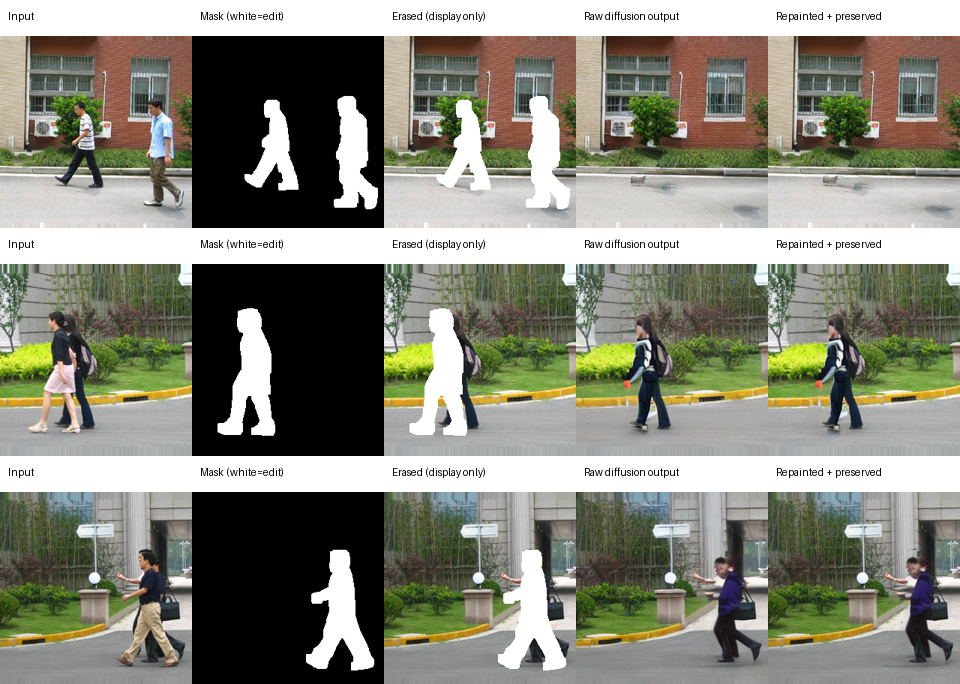

In [8]:
# Saved output from the completed real-photo run (included for preview).
display(Image(filename=str(ROOT / 'outputs/pennfudan/contact_sheet.png')))